# 12B — Measurement-error recovery

**Part 1 · Research question (Q2).** Are Combine → NFL relationships attenuated because tracked Combine predictors are measured unreliably — i.e. are the earlier negative results compatible with realistic measurement-error attenuation?

**Part 2 · Declared hypotheses.** *Primary:* for the preregistered features (`measurement_error.PREREGISTERED`: acceleration 2→4, 4→6, 6→8 yd/s; time 4→8 yd/s; observed top speed; shuttle deceleration; three-cone transition cost) corrected latent coefficients exceed observed ones roughly in proportion to 1/√reliability, while held-out prediction does NOT improve (a correction rescales an association; it does not add information). *Secondary:* the synthetic grid shows where each estimator is unbiased and covers.

**Four estimands, never substituted for each other:** observed association (partial r / standardized slope of the athlete mean given M1) · corrected latent effect (regression calibration, SIMEX, joint EM; disattenuated r) · compatible latent range (observed interval ÷ √(reliabilities)) · out-of-sample value (held-out Δ RMSE of M1 + x̄ and M1 + E[θ | x̄]).

**Model assumptions (stated, not tested by the correction itself):** classical additive error, nondifferential with respect to the NFL target, homoscedastic within position, attempts exchangeable; one attempt per athlete → σ²_ε not identifiable (flagged, never borrowed).

**Prerequisites.** 12.0 (same `RUN_MODE`). 12C is optional here (its frozen target is added when present).

In [1]:
RUN_MODE = 'full'
SEED = 20261015
FORCE_REBUILD = False
SAVE_TABLES = True
SAVE_FIGURES = True
NUM_WORKERS = 0
MEMORY_BUDGET_GB = 2.0
RUN_SYNTHETIC = True     # planted-signal grid (checkpointed per scenario; resumable)
RUN_BAYES = False        # optional PyMC model (B4); minutes to hours

In [2]:
from nflbdb.data.config import Phase01Config, configure_runtime

cfg = Phase01Config.load()
configure_runtime(cfg)

import numpy as np
import polars as pl
from IPython.display import Markdown, display

from nflbdb.research.advanced_movement import config as amc
from nflbdb.research.advanced_movement.artifacts import ResearchStore
from nflbdb.research.advanced_movement.m11 import config as m11c
from nflbdb.research.advanced_movement.m11 import sources as src
from nflbdb.research.advanced_movement.m11 import speed_state as ss
from nflbdb.research.advanced_movement.m12 import advanced_evaluation as ae
from nflbdb.research.advanced_movement.m12 import config as m12c
from nflbdb.research.advanced_movement.m12 import figures as fg
from nflbdb.research.advanced_movement.m12 import foundation as fd
from nflbdb.research.advanced_movement.m12 import measurement_error as me
from nflbdb.research.advanced_movement.m12 import reporting as rp
from nflbdb.research.advanced_movement.m12 import synthesis as sy
from nflbdb.research.advanced_movement.m12 import validation as v12

controls = amc.NotebookControls(run_mode=RUN_MODE, force_rebuild=FORCE_REBUILD, save_figures=SAVE_FIGURES, save_tables=SAVE_TABLES,
                                seed=SEED, num_workers=NUM_WORKERS).validate()
store = ResearchStore(cfg, controls)
amc.seed_everything(controls.seed)
C = m12c.M12Config().for_mode(controls)
S = src.M11Sources(cfg, store, m11c.M11Config().for_mode(controls))
D = fd.M12Data(store, C, S)
PROV = m12c.provenance('12B', controls, C)
W = store.write_frame
MAN = fd.check_foundation(store, C)
label = 'SMOKE — wiring check, numbers are not results' if controls.smoke else 'FULL'
display(Markdown(f'**Run mode: `{controls.run_mode}`** ({label}) · config `{C.hash()}`'))
checks = v12.run_all((*v12.CHECKS_GENERAL, *v12.CHECKS_MEASUREMENT))
display(checks)
v12.assert_all_passed(checks)

**Run mode: `full`** (FULL) · config `c2903a12f8449fa2`

check,status,detail
str,str,str
"""grouped_folds_and_leakage""","""PASS""","""athlete-grouped folds enforced…"
"""block_sees_training_only""","""PASS""","""fold-fitted blocks receive one…"
"""common_cohort_pairing""","""PASS""","""every model of a ladder is sco…"
"""bootstrap_unit_and_seed""","""PASS""","""athlete bootstrap deterministi…"
"""checkpoint_resume_safety""","""PASS""","""completion gate blocks partial…"
"""evidence_tier_rules""","""PASS""","""evidence tiers never promote o…"
"""icc_and_regression_calibration""","""PASS""","""method-of-moments ICC recovers…"
"""simex_and_em_recovery""","""PASS""","""RC and SIMEX reduce attenuatio…"


## Part 3–4 · Data, eligibility and the measurement model

Attempt-level values of the preregistered features (Milestone 11 attempt features; `forty.time_4_8` derived per attempt as `t_to_8 − t_to_4`). Athlete value = mean of attempts (the frozen Milestone 04 rule). NFL targets: the physically matched Milestone 11 targets (supported athletes only) and, when 12C has executed, its frozen `nfl.q90_shared`. NFL target reliability (game split-half) from Milestone 11.

In [3]:
off = D.officials()
POS = dict(zip(off['nfl_id'].to_list(), off['position_group'].to_list()))
long = me.attempt_long(D.attempt_features())
stats = me.athlete_stats(long)
nw = ss.nfl_wide(D.nfl_targets())
if store.has('m12c_targets'):
    nw = nw.join(store.read_frame('m12c_targets', fd.NB['12C']).select('nfl_id', 'nfl.q90_shared'), on='nfl_id', how='left')
REL_Y = {r['target_id']: r['reliability'] for r in D.nfl_target_reliability().iter_rows(named=True)}
fman = D.m12('m12_fold_manifest').select('nfl_id', 'fold')
display(ae.memory_plan([{'item': 'attempt values (preregistered)', 'n_rows': long.height, 'n_cols': 5}], MEMORY_BUDGET_GB))
avail = (long.group_by('feature').agg(pl.col('nfl_id').n_unique().alias('athletes'), pl.len().alias('attempts'))
         .join(stats.filter(pl.col('n_att') >= 2).group_by('feature').len().rename({'len': 'athletes_with_repeat'}), on='feature', how='left'))
display(avail.sort('feature'))
display(pl.DataFrame([{'feature': p.feature, 'target': p.target, 'expected_sign': p.sign, 'note': p.note, 'nfl_reliability': REL_Y.get(p.target)} for p in me.PREREGISTERED]))

item,n_rows,n_cols,est_mb,on_disk_mb,note,budget_mb,within_budget
str,i64,i64,f64,null,str,f64,bool
"""attempt values (preregistered)""",4431,5,0.2,null,"""""",2000.0,true


feature,athletes,attempts,athletes_with_repeat
str,u32,u32,u32
"""forty.band_2_4_mean_accel""",418,790,372
"""forty.band_4_6_mean_accel""",418,793,375
"""forty.band_6_8_mean_accel""",418,793,375
"""forty.time_4_8""",408,728,320
"""forty.v_max_obs""",418,793,375
"""short_shuttle.decel_mean""",169,220,40
"""three_cone.transition_cost_ind…",230,314,73


feature,target,expected_sign,note,nfl_reliability
str,str,i64,str,f64
"""forty.band_2_4_mean_accel""","""nfl.band_2_4""",1,"""acceleration 2→4 yd/s, same ba…",0.976654
"""forty.band_4_6_mean_accel""","""nfl.band_4_6""",1,"""acceleration 4→6 yd/s""",0.957187
"""forty.band_6_8_mean_accel""","""nfl.band_6_8""",1,"""acceleration 6→8 yd/s""",0.781722
"""forty.time_4_8""","""nfl.band_4_6""",-1,"""time from 4 to 8 yd/s (derived…",0.957187
"""forty.v_max_obs""","""nfl.vmax_p90""",1,"""observed Combine top speed vs …",0.816681
"""short_shuttle.decel_mean""","""nfl.brake_decel""",1,"""turning / braking: shuttle dec…",0.84171
"""three_cone.transition_cost_ind…","""nfl.redirect_retention""",-1,"""turning: speed lost through a …",0.59948


## Part 5 · Reliability (B2): variance components, ICC, position, attempt count, censoring

feature,group,n_athletes,n_repeat,sigma2_theta,sigma2_eps,icc,icc_lo,icc_hi,reliability_mean,sb_1,sb_2,sb_3,identifiable
str,str,i64,i64,f64,f64,f64,f64,f64,f64,f64,f64,f64,bool
"""forty.band_2_4_mean_accel""","""ALL""",418,372,0.259125,0.308503,0.456504,0.342305,0.560663,0.608103,0.456504,0.626849,0.715895,true
"""forty.band_2_4_mean_accel""","""ALL|onset_recorded""",408,320,0.271385,0.222141,0.54989,0.435291,0.66109,0.675141,0.54989,0.709586,0.785639,true
"""forty.band_4_6_mean_accel""","""ALL""",418,375,0.513041,0.203021,0.716475,0.6186,0.815754,0.822647,0.716475,0.834822,0.883465,true
"""forty.band_4_6_mean_accel""","""ALL|onset_recorded""",408,320,0.53739,0.150538,0.781172,0.682572,0.858111,0.856444,0.781172,0.877144,0.914599,true
"""forty.band_6_8_mean_accel""","""ALL""",418,375,0.801191,0.139767,0.851463,0.782229,0.918303,0.912746,0.851463,0.919773,0.945046,true
"""forty.band_6_8_mean_accel""","""ALL|onset_recorded""",408,320,0.825176,0.098246,0.893607,0.826977,0.942363,0.932985,0.893607,0.943815,0.961828,true
"""forty.time_4_8""","""ALL""",408,320,0.088478,0.005371,0.942767,0.92781,0.956643,0.96455,0.942767,0.970541,0.980166,true
"""forty.time_4_8""","""ALL|onset_recorded""",408,320,0.088478,0.005371,0.942767,0.92781,0.956643,0.96455,0.942767,0.970541,0.980166,true
"""forty.v_max_obs""","""ALL""",418,375,0.596335,0.009091,0.984984,0.982483,0.987238,0.991669,0.984984,0.992435,0.994944,true


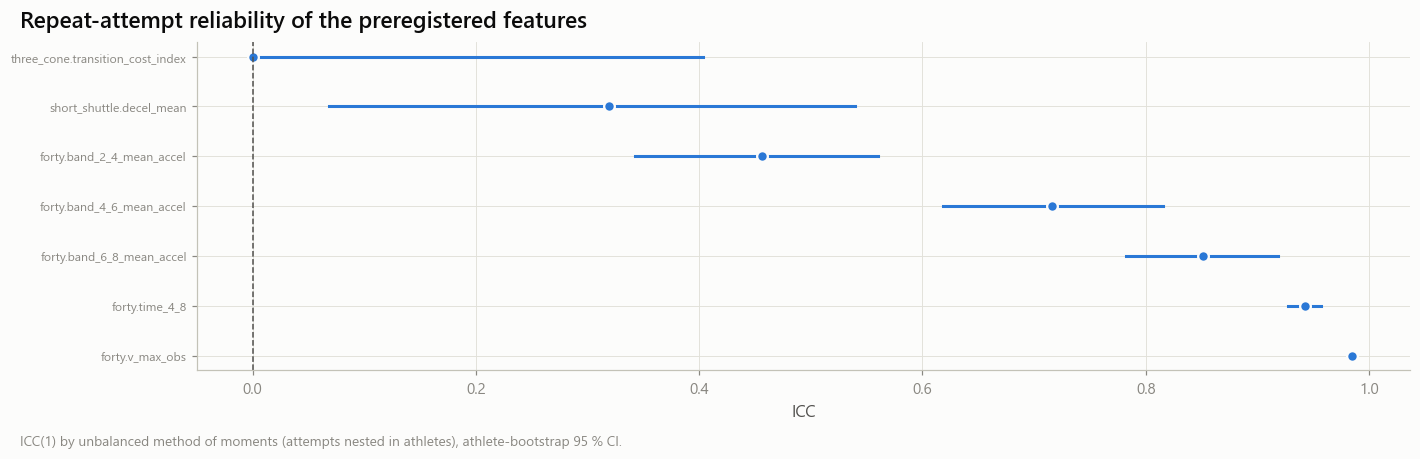

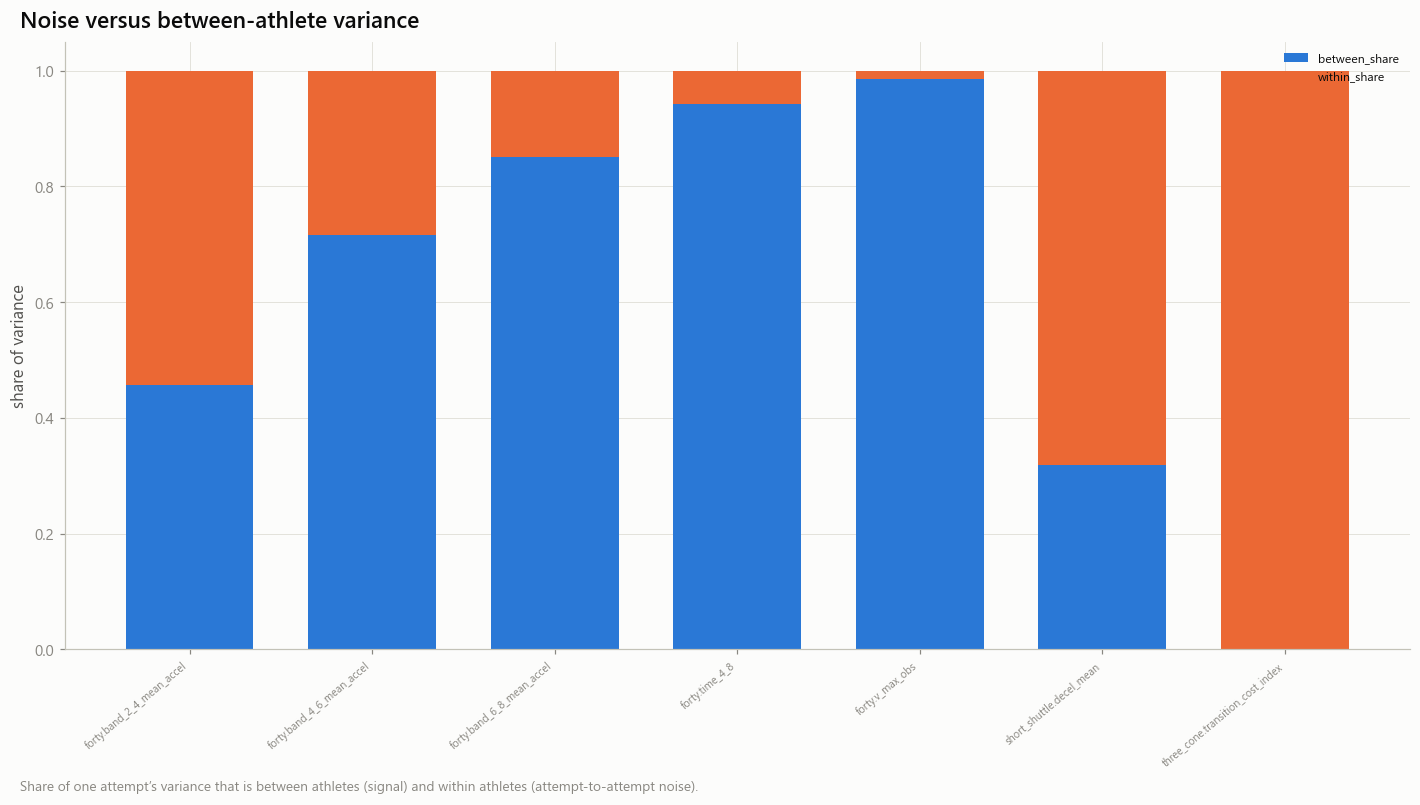

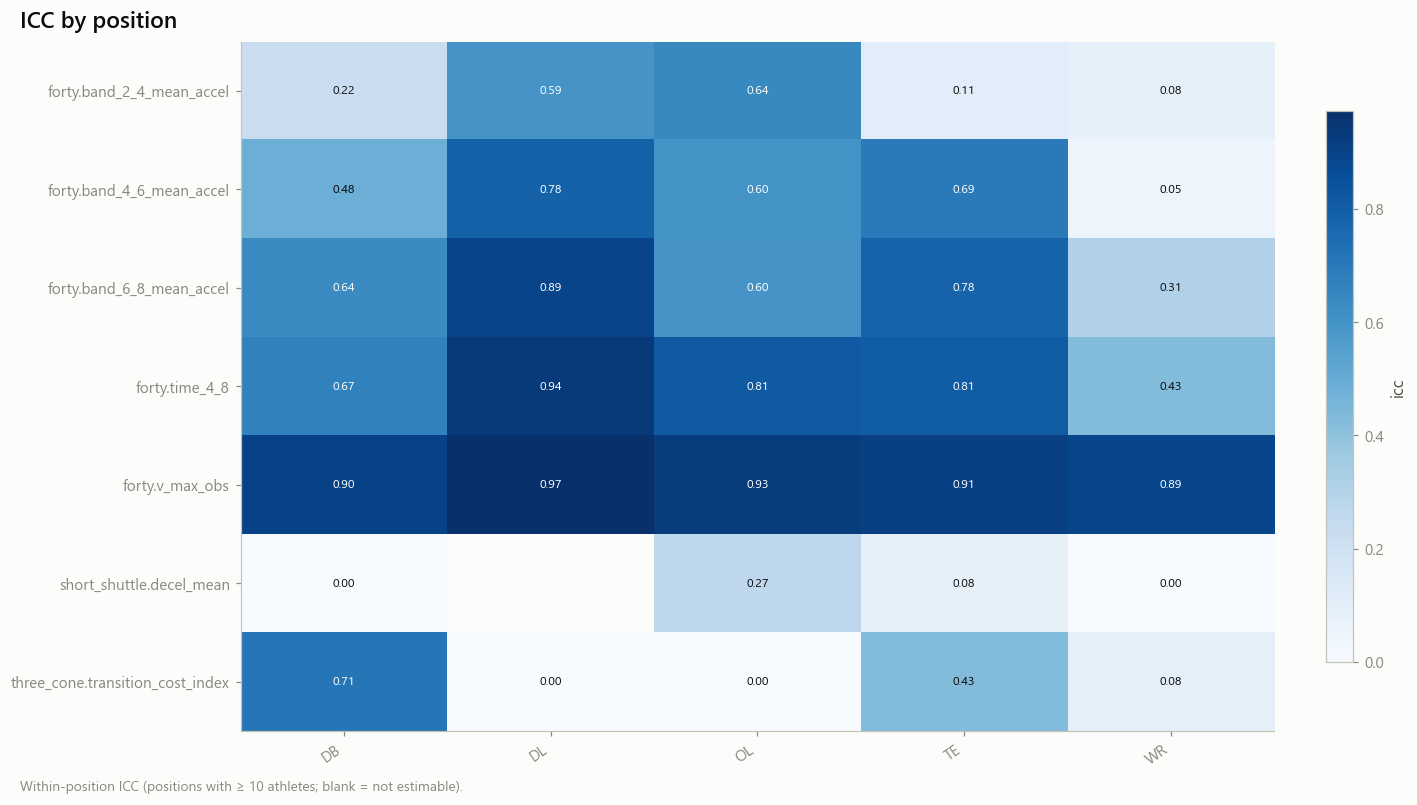

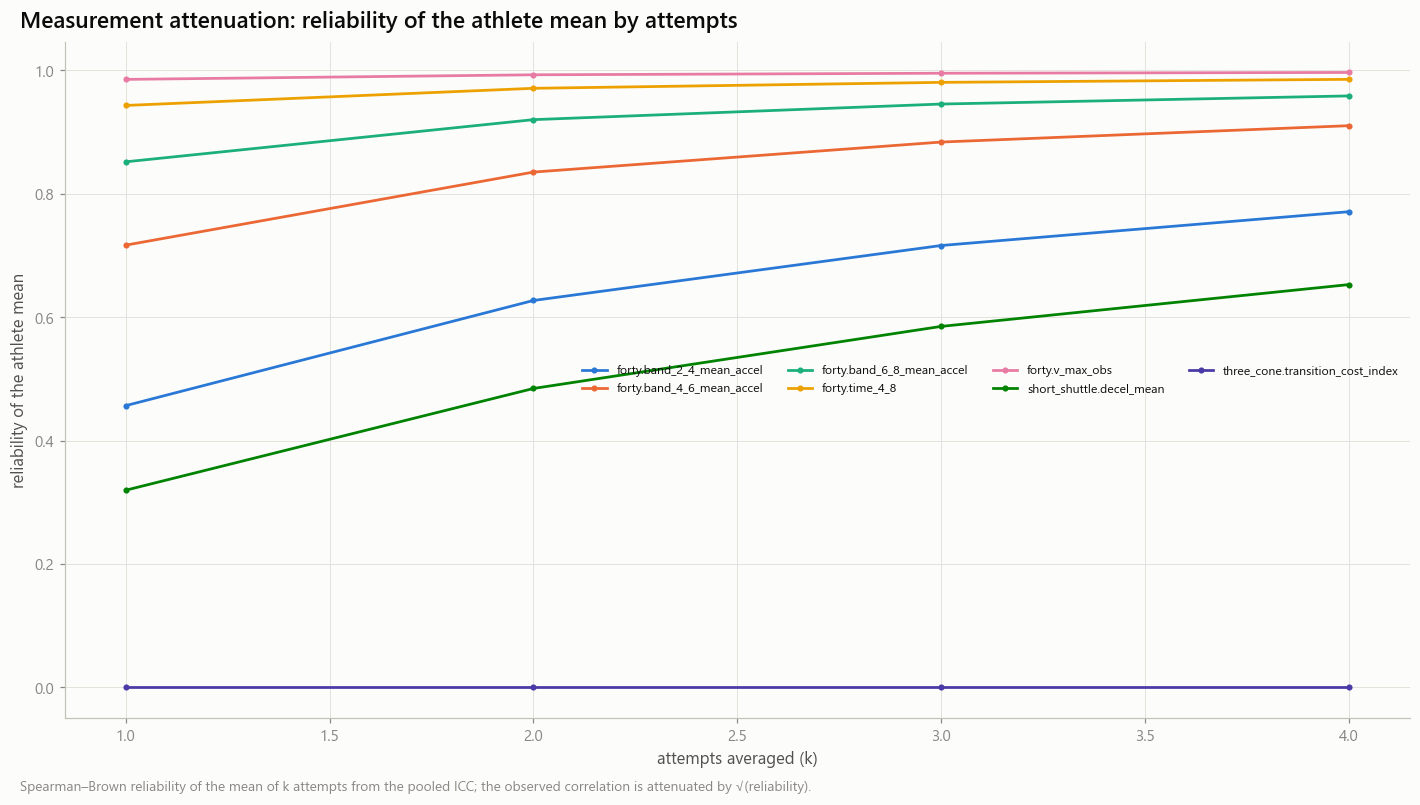

In [4]:
rt = me.reliability_table(long, POS, C, C.seed)
W(rt, 'm12b_reliability')
with pl.Config(tbl_rows=-1, tbl_width_chars=260):
    display(rt.filter(pl.col('group').is_in(['ALL', 'ALL|onset_recorded'])).select('feature', 'group', 'n_athletes', 'n_repeat', 'sigma2_theta', 'sigma2_eps', 'icc', 'icc_lo', 'icc_hi',
                                                                               'reliability_mean', 'sb_1', 'sb_2', 'sb_3', 'identifiable'))
ra = rt.filter(pl.col('group') == 'ALL')
store.show(fg.fig_forest(ra.sort('icc'), 'feature', 'icc', 'icc_lo', 'icc_hi', 'Repeat-attempt reliability of the preregistered features',
                         'ICC(1) by unbalanced method of moments (attempts nested in athletes), athlete-bootstrap 95 % CI.', 'ICC'), 'AM12_B_01_reliability', {'reliability': ra},
           publication=True, source='m12b_reliability')
vs = ra.with_columns((pl.col('sigma2_theta') / (pl.col('sigma2_theta') + pl.col('sigma2_eps'))).alias('between_share'),
                     (pl.col('sigma2_eps') / (pl.col('sigma2_theta') + pl.col('sigma2_eps'))).alias('within_share'))
store.show(fg.fig_stacked(vs, 'feature', ['between_share', 'within_share'], 'Noise versus between-athlete variance', 'Share of one attempt’s variance that is between athletes (signal) and within athletes (attempt-to-attempt noise).', 'share of variance'),
           'AM12_B_02_noise_vs_signal', {'variance': vs}, source='m12b_reliability')
rp_ = rt.filter(~pl.col('group').str.starts_with('ALL'))
store.show(fg.fig_heatmap(rp_, 'feature', 'group', 'icc', 'ICC by position', 'Within-position ICC (positions with ≥ 10 athletes; blank = not estimable).', fmt='{:.2f}'),
           'AM12_B_03_icc_by_position', {'icc_position': rp_}, source='m12b_reliability')
sb = ra.unpivot(index='feature', on=['sb_1', 'sb_2', 'sb_3', 'sb_4'], variable_name='k', value_name='reliability').with_columns(pl.col('k').str.slice(3).cast(pl.Int64))
store.show(fg.fig_lines(sb, 'k', 'reliability', 'feature', 'Measurement attenuation: reliability of the athlete mean by attempts', 'Spearman–Brown reliability of the mean of k attempts from the pooled ICC; the observed correlation is attenuated by √(reliability).',
                        'attempts averaged (k)', 'reliability of the athlete mean'), 'AM12_B_04_attenuation_by_attempts', {'sb': sb}, source='m12b_reliability')

## Part 6–7 · Corrections (B0–B4) on real data and held-out value

Per preregistered feature × matched NFL target: B0 naive slope of x̄ · B1 regression calibration (partial reliability after M1) · B2 SIMEX (λ grid, quadratic extrapolation to −1) · B3 joint EM latent-variable regression · disattenuated partial r · compatible latent range. Held-out: M1 vs M1 + x̄ (B0) vs M1 + E[θ | x̄] (B1; μ, σ²_θ, σ²_ε from TRAINING athletes, within position when ≥ 20) on identical athletes.

In [5]:
est_rows, held_rows, oofs = [], [], []
targets = [(p, p.target) for p in me.PREREGISTERED] + ([(p, 'nfl.q90_shared') for p in me.PREREGISTERED if p.feature.startswith('forty.')] if 'nfl.q90_shared' in nw.columns else [])
for p, tgt in targets:
    if tgt not in nw.columns:
        est_rows.append({'feature': p.feature, 'target': tgt, 'status': 'target_not_available'})
        continue
    st_f = stats.filter(pl.col('feature') == p.feature).select('nfl_id', 'xbar', 'n_att')
    d = off.join(st_f, on='nfl_id', how='inner').join(nw.select('nfl_id', tgt), on='nfl_id', how='inner').join(fman, on='nfl_id', how='inner').filter(pl.col(tgt).is_not_null())
    lf = long.filter(pl.col('feature') == p.feature)
    comp = me.components(lf['value'].to_numpy(), lf['nfl_id'].to_numpy())
    rel_y = REL_Y.get(tgt, np.nan) if tgt != 'nfl.q90_shared' else np.nan
    e = me.estimands(d, 'xbar', tgt, 'n_att', comp['sigma2_eps'] if comp['identifiable'] else np.nan, list(ae.M1_COLS), C, C.seed, rel_y=rel_y)
    em = me.em_estimand(d, long, p.feature, tgt, list(ae.M1_COLS), C, C.seed) if comp['identifiable'] else {'status': 'not_identifiable'}
    k = len(ae.M1_COLS) + max(0, d['position_group'].n_unique() - 1)
    cmp_ = me.compatible_latent(e.get('r_partial_lo', np.nan), e.get('r_partial_hi', np.nan), e.get('rel_x_partial', np.nan), rel_y, d.height, k)
    est_rows.append({'feature': p.feature, 'target': tgt, 'expected_sign': p.sign, 'icc': comp['icc'], 'identifiable': comp['identifiable'], 'rel_y': rel_y,
                     **{kk: v for kk, v in e.items() if kk != 'status'}, 'status': e.get('status'), **{kk: v for kk, v in em.items() if kk not in ('status', 'n_athletes')}, **cmp_})
    if comp['identifiable'] and d.height >= C.min_athletes:
        mods = {'M1': ae.Model(list(ae.M1_COLS)), 'B0': ae.Model([*ae.M1_COLS, 'xbar']),
                'B1': ae.Model(list(ae.M1_COLS), factory=lambda ids, _f=p.feature: me.rc_block(ids, stats, long, _f, POS))}
        res = ae.oof_ladder(d, tgt, mods, C, C.seed)
        held_rows.append(ae.compare(res, [('B0', 'M1'), ('B1', 'M1'), ('B1', 'B0')], C, C.seed, feature=p.feature, target=tgt))
        oofs.append(res.oof_frame(feature=p.feature, target=tgt))
EST = pl.DataFrame(est_rows, infer_schema_length=None)
HELD = pl.concat([h for h in held_rows if h.height], how='diagonal_relaxed') if held_rows else pl.DataFrame()
OOF = pl.concat(oofs, how='diagonal_relaxed') if oofs else pl.DataFrame()
W(EST, 'm12b_estimands')
W(HELD, 'm12b_heldout')
W(OOF, 'm12b_heldout_oof')
with pl.Config(tbl_rows=-1, tbl_width_chars=300):
    display(EST.select([c for c in ('feature', 'target', 'n_athletes', 'icc', 'rel_x_partial', 'beta_obs', 'beta_obs_lo', 'beta_obs_hi', 'beta_rc', 'beta_rc_lo', 'beta_rc_hi',
                                    'beta_simex', 'beta_simex_lo', 'beta_simex_hi', 'beta_em', 'beta_em_lo', 'beta_em_hi', 'r_partial', 'r_disattenuated', 'latent_lo', 'latent_hi', 'mde_latent', 'status') if c in EST.columns]))
    display(HELD.select('feature', 'target', 'model', 'reference', 'n_athletes', 'delta_rmse', 'delta_lo', 'delta_hi', 'verdict') if HELD.height else HELD)

feature,target,n_athletes,icc,rel_x_partial,beta_obs,beta_obs_lo,beta_obs_hi,beta_rc,beta_rc_lo,beta_rc_hi,beta_simex,beta_simex_lo,beta_simex_hi,beta_em,beta_em_lo,beta_em_hi,r_partial,r_disattenuated,latent_lo,latent_hi,mde_latent,status
str,str,i64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,str
"""forty.band_2_4_mean_accel""","""nfl.band_2_4""",309,0.456504,0.508434,-0.018439,-0.118628,0.109464,-0.02586,-0.160168,0.176736,-0.029692,-0.133916,0.109573,0.001942,-0.057403,0.067476,-0.018439,-0.026167,-0.168344,0.155341,0.228684,"""computed"""
"""forty.band_4_6_mean_accel""","""nfl.band_4_6""",237,0.716475,0.414225,-0.037087,-0.157056,0.107658,-0.057625,-0.269015,0.196818,-0.044481,-0.156192,0.088156,-0.018207,-0.088203,0.044421,-0.037087,-0.058899,-0.249423,0.170974,0.293215,"""computed"""
"""forty.band_6_8_mean_accel""","""nfl.band_6_8""",120,0.851463,0.68645,-0.079331,-0.246507,0.11798,-0.09575,-0.289761,0.160389,-0.078535,-0.231749,0.073342,-0.106764,-0.277922,0.049871,-0.079331,-0.108296,-0.336511,0.161056,0.357773,"""computed"""
"""forty.time_4_8""","""nfl.band_4_6""",230,0.942767,0.563254,0.04414,-0.086662,0.178203,0.058813,-0.113702,0.244812,0.061387,-0.128048,0.186865,0.010295,-0.035734,0.057616,0.04414,0.060114,-0.118026,0.242697,0.255362,"""computed"""
"""forty.v_max_obs""","""nfl.vmax_p90""",150,0.984984,0.789806,0.271669,0.10998,0.42495,0.305689,0.123634,0.479646,0.299302,0.151232,0.470024,0.209756,0.102867,0.335514,0.271669,0.338263,0.136939,0.529117,0.29043,"""computed"""
"""short_shuttle.decel_mean""","""nfl.brake_decel""",111,0.319528,0.001,-0.005944,-0.142749,0.151747,-0.187964,-4.514127,4.798672,-0.000234,-0.006568,0.009169,-0.00912,-0.156227,0.224896,-0.005944,-0.204877,-1.0,1.0,1.0,"""computed"""
"""three_cone.transition_cost_ind…","""nfl.redirect_retention""",85,0.0,0.001,0.03397,-0.170386,0.290373,1.074222,-5.388081,9.182387,0.001983,-0.009946,0.01575,0.292239,-0.484183,0.578683,0.03397,1.387416,-1.0,1.0,1.0,"""computed"""
"""forty.band_2_4_mean_accel""","""nfl.q90_shared""",267,0.456504,0.522581,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"""computed"""
"""forty.band_4_6_mean_accel""","""nfl.q90_shared""",267,0.716475,0.497646,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"""computed"""


feature,target,model,reference,n_athletes,delta_rmse,delta_lo,delta_hi,verdict
str,str,str,str,i64,f64,f64,f64,str
"""forty.band_2_4_mean_accel""","""nfl.band_2_4""","""B0""","""M1""",309,0.000397,-0.000343,0.001241,"""inconclusive"""
"""forty.band_2_4_mean_accel""","""nfl.band_2_4""","""B1""","""M1""",309,0.000463,-0.000668,0.001621,"""inconclusive"""
"""forty.band_2_4_mean_accel""","""nfl.band_2_4""","""B1""","""B0""",309,0.000066,-0.000708,0.000809,"""inconclusive"""
"""forty.band_4_6_mean_accel""","""nfl.band_4_6""","""B0""","""M1""",237,-0.000656,-0.00151,0.000265,"""inconclusive"""
"""forty.band_4_6_mean_accel""","""nfl.band_4_6""","""B1""","""M1""",237,-0.001769,-0.00335,-0.000243,"""model_worse"""
"""forty.band_4_6_mean_accel""","""nfl.band_4_6""","""B1""","""B0""",237,-0.001113,-0.002467,0.000268,"""inconclusive"""
"""forty.band_6_8_mean_accel""","""nfl.band_6_8""","""B0""","""M1""",120,-0.000983,-0.002377,0.000634,"""inconclusive"""
"""forty.band_6_8_mean_accel""","""nfl.band_6_8""","""B1""","""M1""",120,0.000087,-0.002068,0.002322,"""inconclusive"""
"""forty.band_6_8_mean_accel""","""nfl.band_6_8""","""B1""","""B0""",120,0.00107,-0.000526,0.002741,"""inconclusive"""


## Part 8a · Synthetic recovery experiments (B4) — software / statistical behaviour only

Planted latent traits with ICC ∈ {0.2, 0.4, 0.6, 0.8}, 1–3 attempts, β ∈ {0, 0.3}; plus differential (correlated) errors, θ-dependent loss of repeat attempts (MNAR), position structure and a small cohort. Per estimator: bias, RMSE, coverage of the true β, false-positive rate under β = 0, identifiability. Checkpointed per scenario (immutable shards; an interrupted run resumes). These results describe estimators — never NFL transfer.

In [6]:
SIM, SIMS = pl.DataFrame(), pl.DataFrame()
if RUN_SYNTHETIC:
    grid = me.scenario_grid()
    ck = ae.experiment_checkpoint(store, 'm12b_synthetic', C, [], {'scenarios': [s.name for s in grid], 'reps': C.sim_reps})
    prog = m11c.Progress(len(grid), '12B synthetic', every_s=20)
    for s in grid:
        if not ck.has(s.name):
            ck.save(s.name, me.run_scenario(s, C, C.seed))
        prog.step(note=s.name)
    ae.require_complete(ck, [s.name for s in grid], '12B synthetic grid')
    SIM = ck.collect([s.name for s in grid])
    SIMS = me.scenario_summary(SIM)
W(SIM, 'm12b_synthetic_replicates')
W(SIMS, 'm12b_synthetic_summary')
with pl.Config(tbl_rows=60, tbl_width_chars=240):
    display(SIMS)

[12B synthetic] 1/32 · elapsed 1s · ETA 35s icc0.2_k1_b0.0
[12B synthetic] 3/32 · elapsed 94s · ETA 910s icc0.2_k2_b0.0
[12B synthetic] 4/32 · elapsed 195s · ETA 1,363s icc0.2_k2_b0.3
[12B synthetic] 5/32 · elapsed 273s · ETA 1,474s icc0.2_k3_b0.0
[12B synthetic] 6/32 · elapsed 373s · ETA 1,616s icc0.2_k3_b0.3
[12B synthetic] 9/32 · elapsed 437s · ETA 1,117s icc0.4_k2_b0.0
[12B synthetic] 10/32 · elapsed 540s · ETA 1,188s icc0.4_k2_b0.3
[12B synthetic] 11/32 · elapsed 595s · ETA 1,136s icc0.4_k3_b0.0
[12B synthetic] 12/32 · elapsed 696s · ETA 1,160s icc0.4_k3_b0.3
[12B synthetic] 15/32 · elapsed 750s · ETA 850s icc0.6_k2_b0.0
[12B synthetic] 16/32 · elapsed 844s · ETA 844s icc0.6_k2_b0.3
[12B synthetic] 17/32 · elapsed 893s · ETA 788s icc0.6_k3_b0.0
[12B synthetic] 18/32 · elapsed 973s · ETA 756s icc0.6_k3_b0.3
[12B synthetic] 21/32 · elapsed 1,023s · ETA 536s icc0.8_k2_b0.0
[12B synthetic] 22/32 · elapsed 1,094s · ETA 497s icc0.8_k2_b0.3
[12B synthetic] 23/32 · elapsed 1,140s · ETA 44

scenario,estimator,n_reps,identifiable_share,bias,rmse,coverage,false_positive_rate
str,str,i64,f64,f64,f64,f64,f64
"""correlated_err_b0.0""","""beta_obs""",200,1.0,0.171692,0.18081,0.135,0.865
"""correlated_err_b0.0""","""beta_rc""",200,1.0,0.211592,0.223021,0.135,0.865
"""correlated_err_b0.0""","""beta_simex""",200,1.0,0.187986,0.198761,0.11,0.89
"""correlated_err_b0.0""","""beta_em""",200,1.0,0.211592,0.223021,null,null
"""correlated_err_b0.3""","""beta_obs""",200,1.0,-0.089126,0.095416,0.03,NaN
"""correlated_err_b0.3""","""beta_rc""",200,1.0,0.09763,0.107174,0.105,NaN
"""correlated_err_b0.3""","""beta_simex""",200,1.0,-0.012229,0.040447,0.685,NaN
"""correlated_err_b0.3""","""beta_em""",200,1.0,0.073627,0.078906,null,null
"""icc0.2_k1_b0.0""","""beta_obs""",200,0.0,-0.003253,0.058199,NaN,NaN


In [7]:
BAYES = {}
if RUN_BAYES and me.bayes_available():
    p = me.PREREGISTERED[4]
    d = off.join(stats.filter(pl.col('feature') == p.feature), on='nfl_id').join(nw.select('nfl_id', p.target), on='nfl_id').filter(pl.col(p.target).is_not_null())
    xs = [g['value'].to_numpy() for _, g in sorted(long.filter((pl.col('feature') == p.feature) & pl.col('nfl_id').is_in(d['nfl_id'].to_list())).partition_by(['nfl_id'], as_dict=True).items())]
    d = d.sort('nfl_id')
    BAYES = me.fit_bayes(xs, d[p.target].to_numpy(), me._covariates(d, list(ae.M1_COLS)), seed=C.seed)
    if controls.save_tables:
        store.write_json('m12b_bayes', {'feature': p.feature, 'target': p.target, **BAYES})
    display(pl.DataFrame(BAYES['summary']))
    print(f"max R-hat {BAYES['r_hat_max']:.3f} · min bulk ESS {BAYES['ess_bulk_min']:.0f} (R-hat > 1.01 or ESS < 400 → do not interpret)")
else:
    print('B4 Bayesian model:', 'not requested (RUN_BAYES = False)' if not RUN_BAYES else 'PyMC not installed — not_feasible')

B4 Bayesian model: not requested (RUN_BAYES = False)


## Part 8b–9 · Uncertainty, calibration and figures

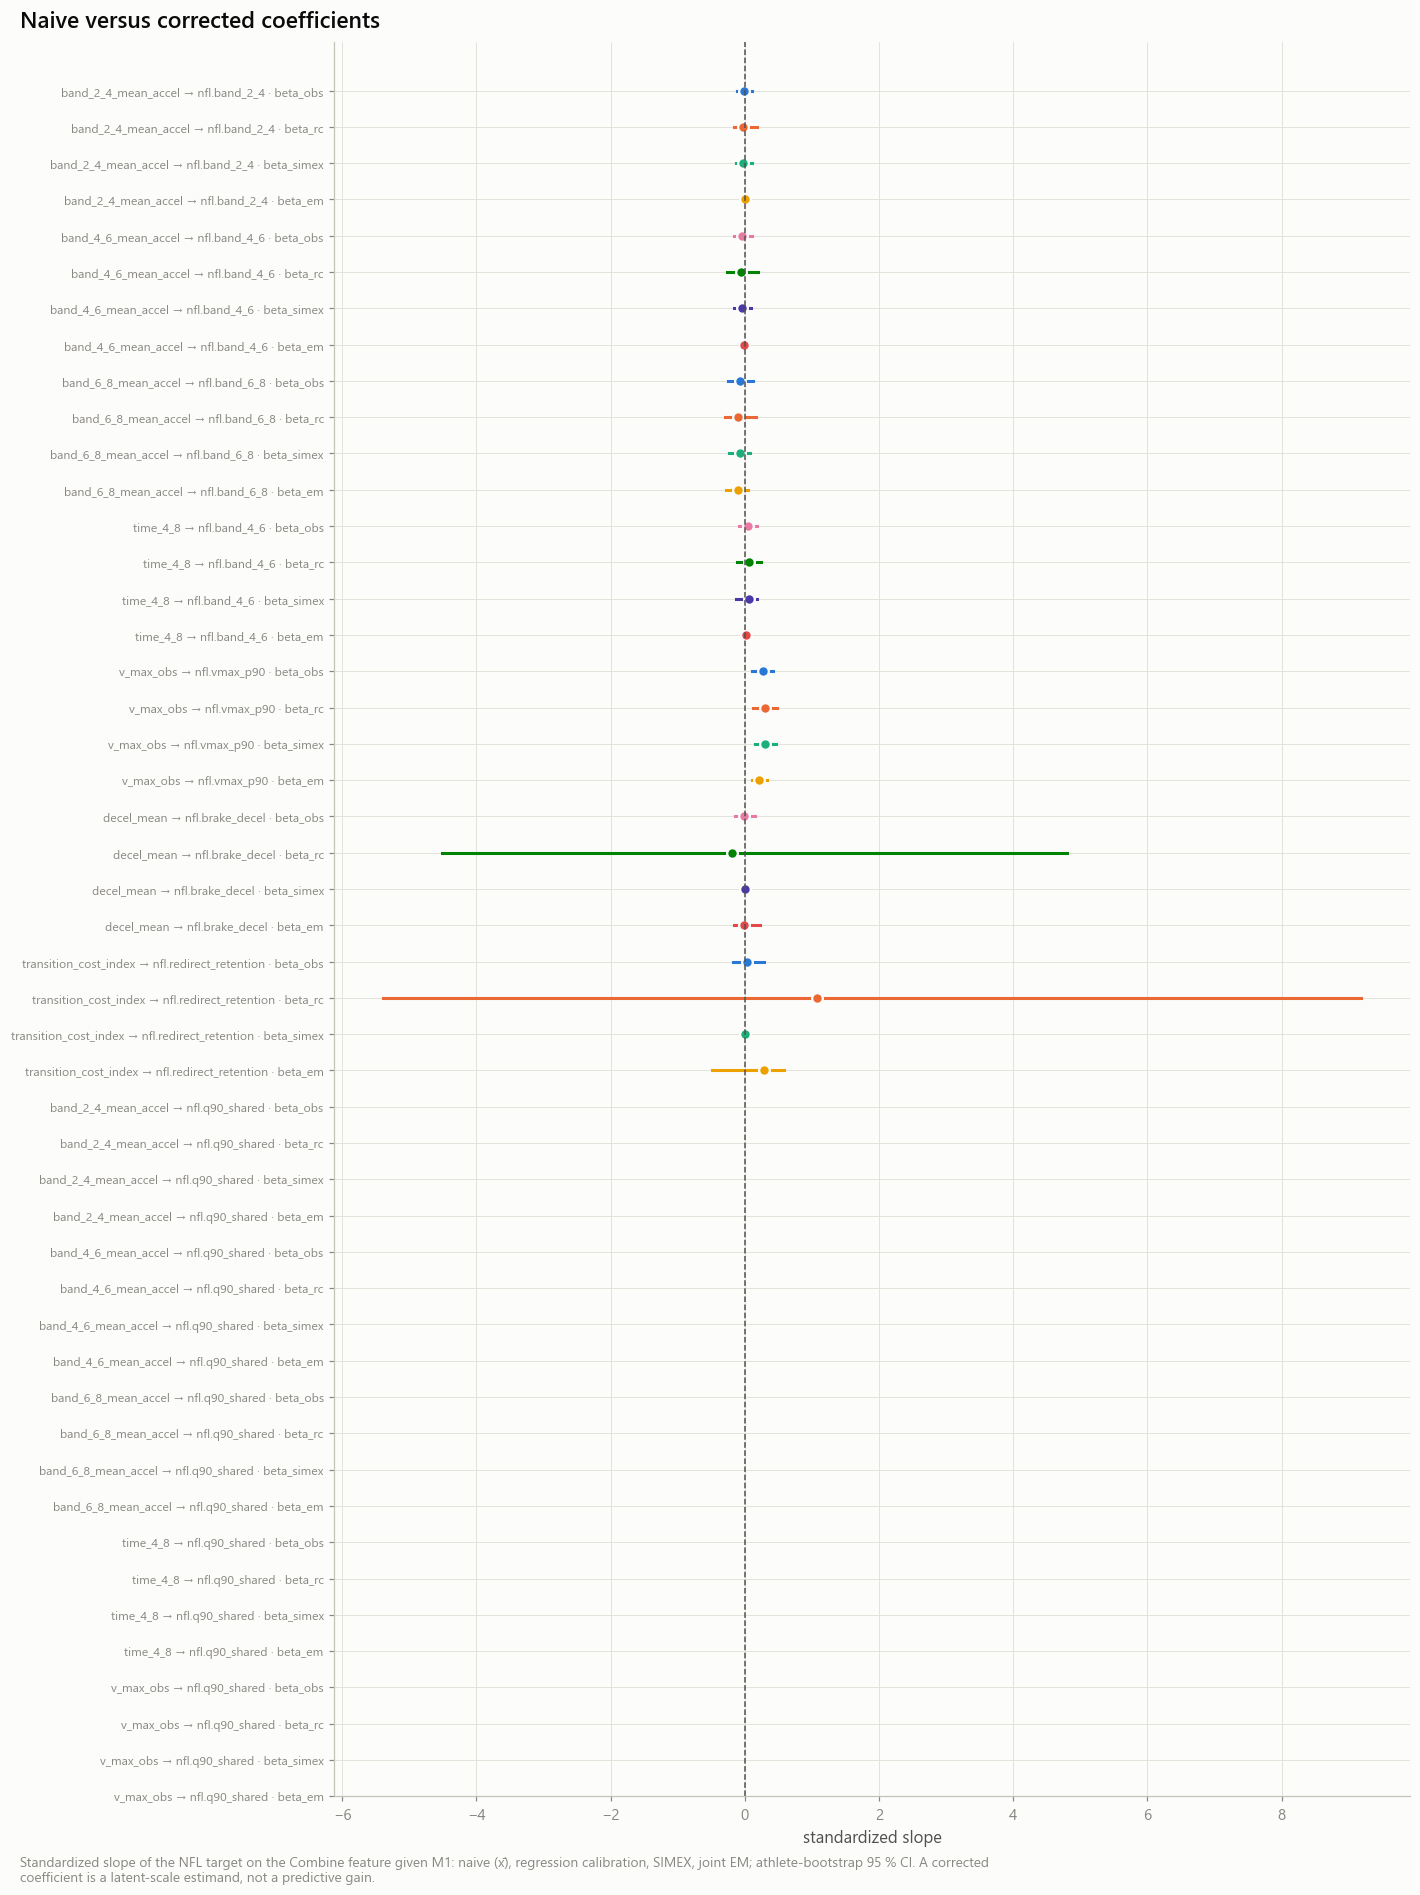

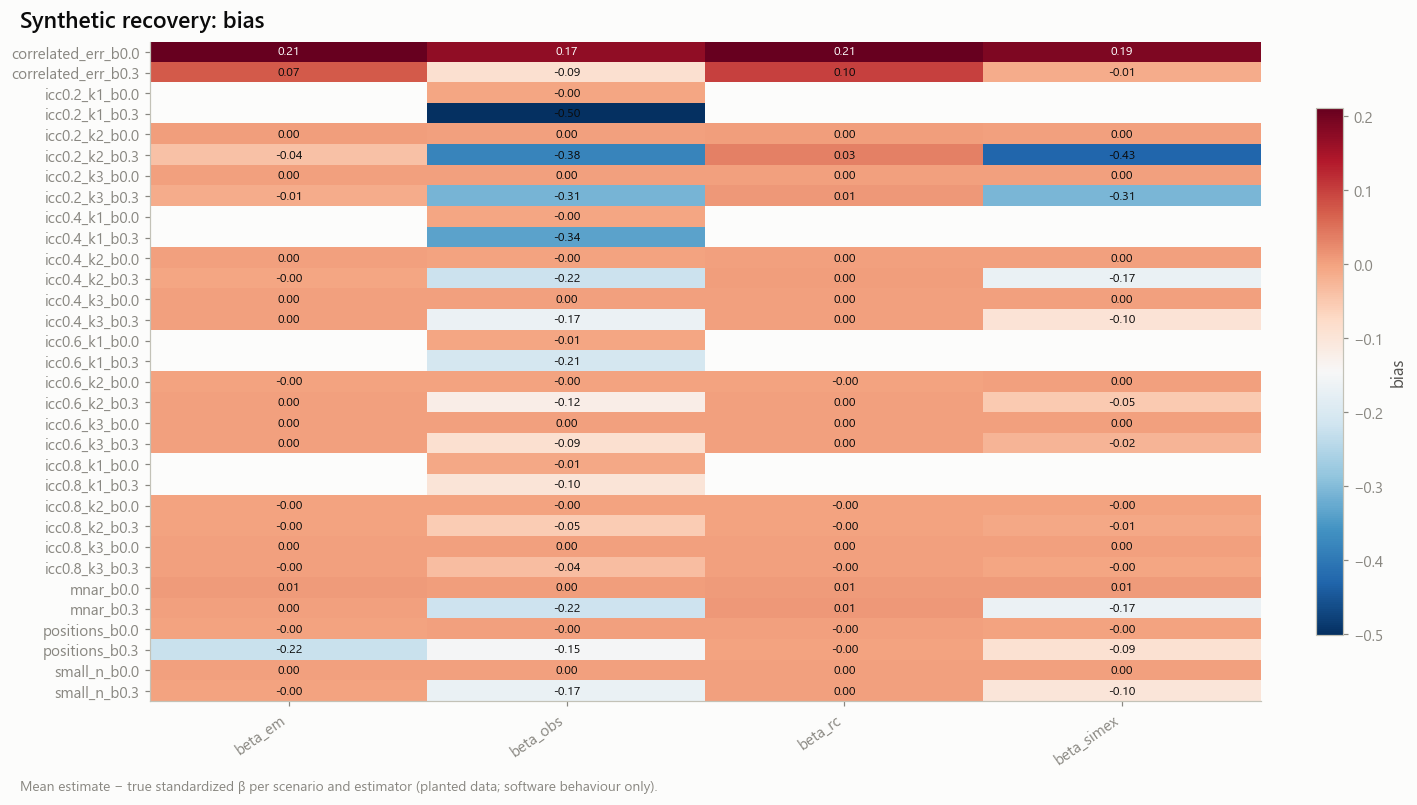

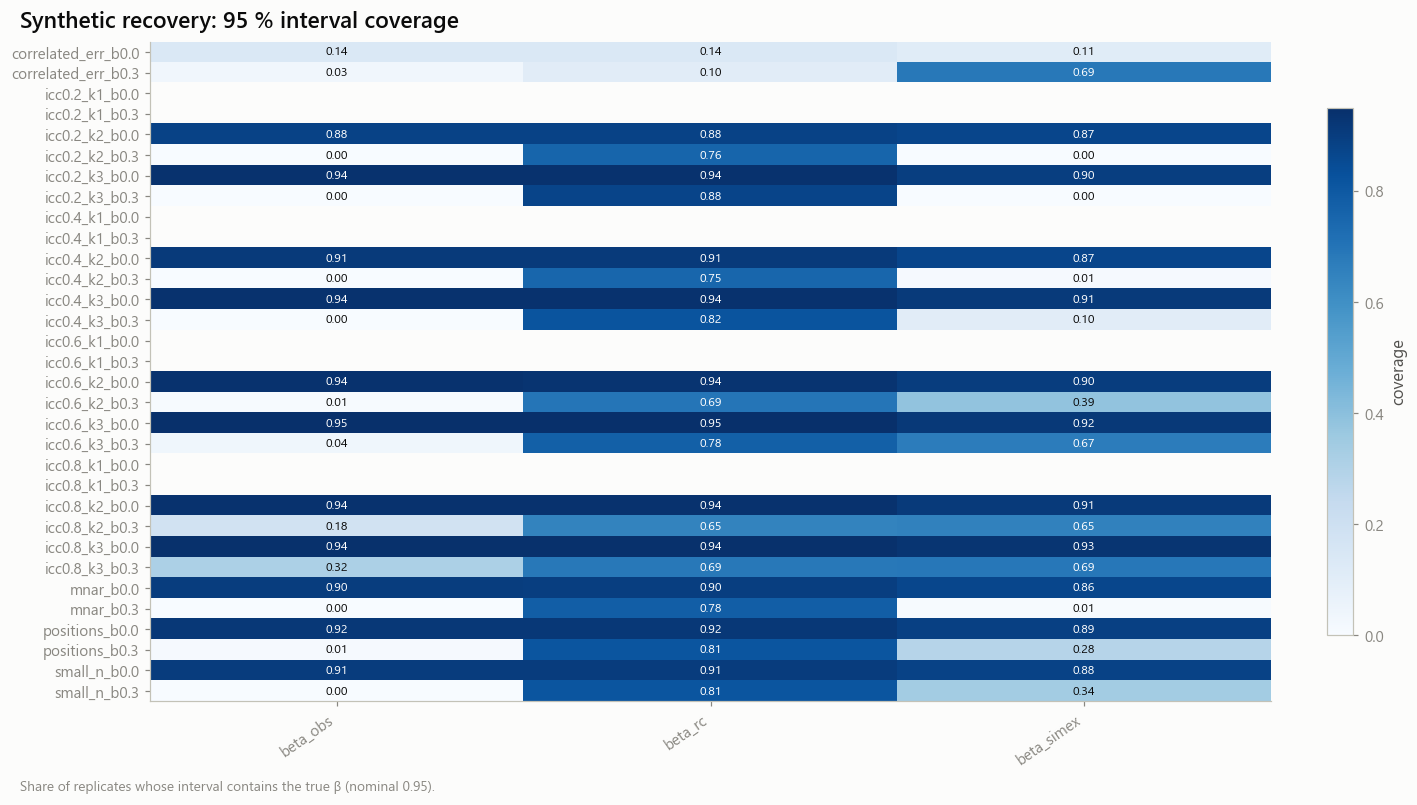

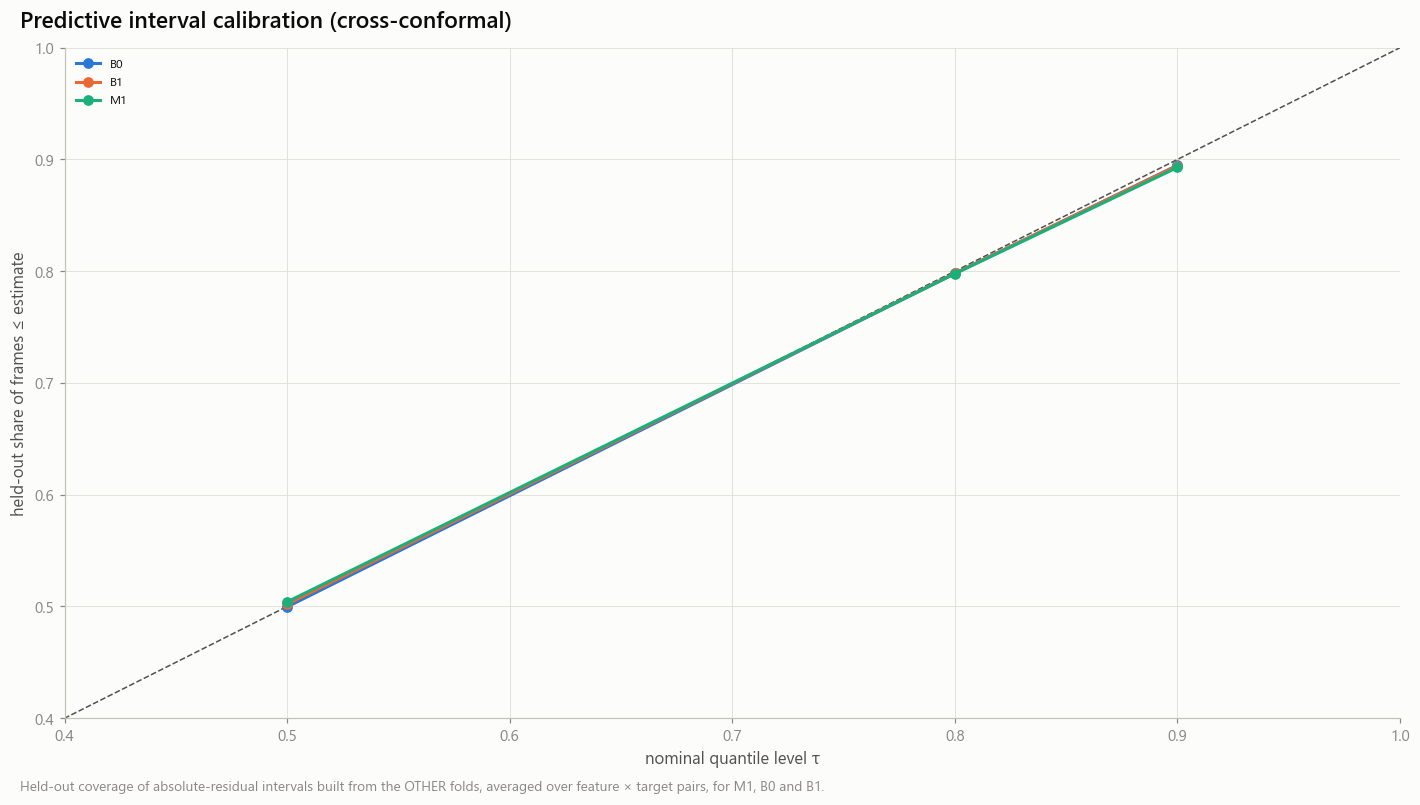

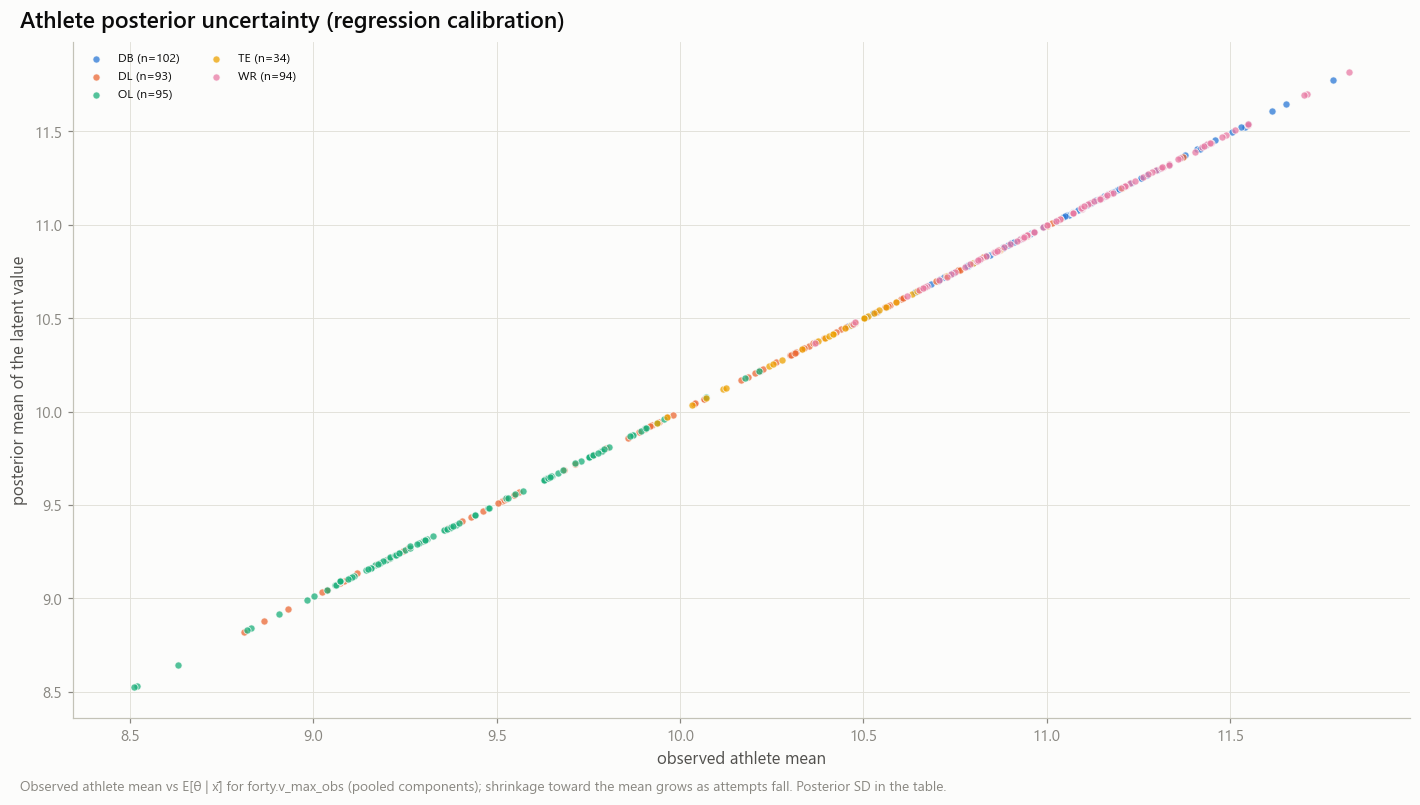

In [8]:
ok = EST.filter(pl.col('status') == 'computed') if 'status' in EST.columns else EST
cl = []
for r in ok.iter_rows(named=True):
    for k in ('beta_obs', 'beta_rc', 'beta_simex', 'beta_em'):
        if r.get(k) is not None:
            cl.append({'label': f"{r['feature'].split('.', 1)[-1]} → {r['target']} · {k}", 'estimator': k, 'est': r[k], 'lo': r.get(f'{k}_lo'), 'hi': r.get(f'{k}_hi')})
cl = pl.DataFrame(cl, infer_schema_length=None)
store.show(fg.fig_forest(cl, 'label', 'est', 'lo', 'hi', 'Naive versus corrected coefficients', 'Standardized slope of the NFL target on the Combine feature given M1: naive (x̄), regression calibration, SIMEX, joint EM; athlete-bootstrap 95 % CI. A corrected coefficient is a latent-scale estimand, not a predictive gain.',
                         'standardized slope', color_by='estimator'), 'AM12_B_05_naive_vs_corrected', {'coefficients': cl}, publication=True, source='m12b_estimands')
if SIMS.height:
    store.show(fg.fig_heatmap(SIMS, 'scenario', 'estimator', 'bias', 'Synthetic recovery: bias', 'Mean estimate − true standardized β per scenario and estimator (planted data; software behaviour only).', fmt='{:.2f}', cmap='RdBu_r'),
               'AM12_B_06_synthetic_bias', {'synthetic': SIMS}, source='m12b_synthetic_summary')
    if 'coverage' in SIMS.columns:
        store.show(fg.fig_heatmap(SIMS.filter(pl.col('coverage').is_not_null()), 'scenario', 'estimator', 'coverage', 'Synthetic recovery: 95 % interval coverage',
                                  'Share of replicates whose interval contains the true β (nominal 0.95).', fmt='{:.2f}'), 'AM12_B_07_synthetic_coverage', {}, source='m12b_synthetic_summary')
cal = []
if OOF.height:
    for (f_, t_), g in OOF.partition_by(['feature', 'target'], as_dict=True).items():
        for m_ in ('pred_M1', 'pred_B0', 'pred_B1'):
            if m_ not in g.columns:
                continue
            y, p_, fo = g['y'].to_numpy(), g[m_].to_numpy(), g['fold'].to_numpy()
            for lvl in (0.5, 0.8, 0.9):
                cov = []
                for fk in np.unique(fo):
                    q = np.quantile(np.abs(y[fo != fk] - p_[fo != fk]), lvl)
                    cov += (np.abs(y[fo == fk] - p_[fo == fk]) <= q).tolist()
                cal.append({'feature': f_, 'target': t_, 'model': m_.removeprefix('pred_'), 'nominal': lvl, 'coverage': float(np.mean(cov))})
cal = pl.DataFrame(cal)
W(cal, 'm12b_interval_calibration')
if cal.height:
    cg = cal.group_by('model', 'nominal').agg(pl.col('coverage').mean()).with_columns(pl.col('nominal').alias('tau'), pl.col('model').alias('estimator'))
    store.show(fg.fig_calibration(cg, 'Predictive interval calibration (cross-conformal)', 'Held-out coverage of absolute-residual intervals built from the OTHER folds, averaged over feature × target pairs, for M1, B0 and B1.'),
               'AM12_B_08_interval_calibration', {'calibration': cg}, source='m12b_heldout_oof')
p = me.PREREGISTERED[4]
lf = long.filter(pl.col('feature') == p.feature)
comp = me.components(lf['value'].to_numpy(), lf['nfl_id'].to_numpy())
if comp['identifiable']:
    post = stats.filter(pl.col('feature') == p.feature).with_columns(
        (comp['sigma2_theta'] / (comp['sigma2_theta'] + comp['sigma2_eps'] / pl.col('n_att'))).alias('lam'))
    post = post.with_columns((comp['mean'] + pl.col('lam') * (pl.col('xbar') - comp['mean'])).alias('posterior_mean'),
                             (pl.col('lam') * comp['sigma2_eps'] / pl.col('n_att')).sqrt().alias('posterior_sd')).join(off.select('nfl_id', 'position_group'), on='nfl_id')
    store.show(fg.fig_scatter(post, 'xbar', 'posterior_mean', 'Athlete posterior uncertainty (regression calibration)', f'Observed athlete mean vs E[θ | x̄] for {p.feature} (pooled components); shrinkage toward the mean grows as attempts fall. Posterior SD in the table.',
                              'observed athlete mean', 'posterior mean of the latent value', ref_line='identity'), 'AM12_B_09_posterior_uncertainty', {'posterior': post}, source='m12b_reliability')

## Part 10–12 · Conclusions, comparisons for 12G, artifacts, next questions

In [9]:
rm = controls.run_mode
comps, ev_rows = [], []
for r in (HELD.iter_rows(named=True) if HELD.height else []):
    comps.append(sy.comparison_row('12B', f"{r['model']} vs {r['reference']}: {r['feature']} → {r['target']}", 'Δ RMSE', r['delta_rmse'], r['delta_lo'], r['delta_hi'], r['n_athletes'],
                                   m12c.PHYSICAL_TRANSFER, 'm12b_heldout', rm, experiment=2, primary=(r['model'], r['reference']) == ('B1', 'B0')))
for r in ok.iter_rows(named=True):
    better = 'positive' if r.get('expected_sign', 1) > 0 else 'negative'
    for k in ('beta_obs', 'beta_rc', 'beta_simex', 'beta_em'):
        if r.get(k) is not None:
            comps.append(sy.comparison_row('12B', f"{k}: {r['feature']} → {r['target']}", k, r[k], r.get(f'{k}_lo'), r.get(f'{k}_hi'), r['n_athletes'], m12c.PHYSICAL_TRANSFER,
                                           'm12b_estimands', rm, experiment=2, better=better))
    h = HELD.filter((pl.col('feature') == r['feature']) & (pl.col('target') == r['target']) & (pl.col('model') == 'B1') & (pl.col('reference') == 'M1')) if HELD.height else HELD
    h = h.row(0, named=True) if h.height else {}
    rr = rt.filter((pl.col('feature') == r['feature']) & (pl.col('group') == 'ALL'))
    rr = rr.row(0, named=True) if rr.height else {}
    ev_rows.append(ae.evidence_row(f"12B.RC.{r['feature']}→{r['target']}", '12B', experiment='2', physical_interpretation='regression-calibrated athlete value of the feature',
                                   input_data='m11_attempt_features', output=r['target'], n_athletes=r['n_athletes'], reliability=rr.get('icc'), reliability_lo=rr.get('icc_lo'),
                                   reliability_hi=rr.get('icc_hi'), cross_domain_stat=r.get('r_partial'), cross_domain_lo=r.get('r_partial_lo'), cross_domain_hi=r.get('r_partial_hi'),
                                   delta_rmse=h.get('delta_rmse'), delta_lo=h.get('delta_lo'), delta_hi=h.get('delta_hi'), compute_cost='seconds',
                                   evaluation_target=m12c.PHYSICAL_TRANSFER, training_regime=m12c.INDUCTIVE, run_mode=rm, config_hash=C.hash()))
COMP, EVID = sy.comparison_frame(comps), ae.evidence_frame(ev_rows)
W(COMP, 'm12b_comparisons')
W(EVID, 'm12b_evidence')
prim = [r['verdict'] for r in COMP.filter(pl.col('primary')).iter_rows(named=True)]
status = rp.status_from(prim)
facts = {'status': status, 'run_mode': rm,
         'sample': f"{long['nfl_id'].n_unique()} athletes with preregistered attempt values; {stats.filter(pl.col('n_att') >= 2)['nfl_id'].n_unique()} with a repeat attempt of ≥ 1 feature.",
         'evidence': [f"{r['feature']}: ICC {rp.ci(r['icc'], r['icc_lo'], r['icc_hi'])} (n={r['n_athletes']}, repeats {r['n_repeat']})" for r in ra.iter_rows(named=True)]
                     + [f"{r['feature']} → {r['target']}: β_obs {rp.ci(r.get('beta_obs'), r.get('beta_obs_lo'), r.get('beta_obs_hi'))}, β_RC {rp.ci(r.get('beta_rc'), r.get('beta_rc_lo'), r.get('beta_rc_hi'))}, "
                        f"compatible latent r [{rp.fmt(r.get('latent_lo'))}, {rp.fmt(r.get('latent_hi'))}], detectable latent r ≥ {rp.fmt(r.get('mde_latent'))}" for r in ok.iter_rows(named=True)]
                     + [f"held-out B1 vs B0 ({r['feature']} → {r['target']}): Δ RMSE {rp.ci(r['delta_rmse'], r['delta_lo'], r['delta_hi'], 4)} — {r['verdict']}" for r in (HELD.filter(pl.col('model') == 'B1').filter(pl.col('reference') == 'B0').iter_rows(named=True) if HELD.height else [])],
         'alternatives': ['Errors may be differential (a nervous athlete is slow in every attempt and in games): RC / SIMEX then over-correct (see the synthetic correlated-error scenario).',
                          'Repeat attempts are not missing at random (fatigue, injury, invitation): σ²_ε may be underestimated (see the MNAR scenario).'],
         'relevance': 'Distinguishes “the Combine feature is too noisy to show a relation” from “there is no relation of a detectable size”.',
         'limitations': ['1–3 attempts per athlete: within-athlete variance is imprecise.', 'Corrections assume classical nondifferential error.', 'One cohort.'],
         'next': ['If compatible latent ranges are narrow and near 0 → stop correction work; otherwise collect more repeats per athlete.']}
md = rp.conclusion_markdown('12B', facts)
display(Markdown(md))
rp.write_conclusion(store, '12B', md)
rp.update_doc(store, 'MEASUREMENT_ERROR.md', md + chr(10) + '### Estimands' + chr(10) + chr(10) + rp.md_table(ok, ['feature', 'target', 'n_athletes', 'beta_obs', 'beta_rc', 'beta_simex', 'beta_em', 'latent_lo', 'latent_hi', 'mde_latent']))
rp.run_manifest(store, '12B', PROV, ['m12b_reliability', 'm12b_estimands', 'm12b_heldout', 'm12b_synthetic_summary', 'm12b_comparisons', 'm12b_evidence'], status)
print('Send back: checks, reliability table, estimands and held-out tables, the synthetic summary, the conclusion.')
print('Next: 12a_functional_movement_transfer.ipynb')

## 12B — conclusion (inconclusive; run mode full; generated 2026-10-15T01:18:06Z)

### Research question
Q2 — Could unreliable Combine features be masking athlete-level relationships?

### Declared primary hypothesis
For preregistered features, corrected latent associations exceed observed ones in proportion to 1/√ICC, but held-out prediction does not improve.

### Primary outcome / comparison
corrected vs naive standardized coefficient of each preregistered feature on its matched NFL target — regression calibration (B1) vs naive (B0) held-out Δ RMSE; SIMEX / EM coefficients descriptive (evaluation target: `cross_domain_physical_transfer`)

### Sample
460 athletes with preregistered attempt values; 395 with a repeat attempt of ≥ 1 feature.

### Main evidence (from persisted tables)
- forty.band_2_4_mean_accel: ICC 0.457 [0.342, 0.561] (n=418, repeats 372)
- forty.band_4_6_mean_accel: ICC 0.716 [0.619, 0.816] (n=418, repeats 375)
- forty.band_6_8_mean_accel: ICC 0.851 [0.782, 0.918] (n=418, repeats 375)
- forty.time_4_8: ICC 0.943 [0.928, 0.957] (n=408, repeats 320)
- forty.v_max_obs: ICC 0.985 [0.982, 0.987] (n=418, repeats 375)
- short_shuttle.decel_mean: ICC 0.320 [0.068, 0.540] (n=169, repeats 40)
- three_cone.transition_cost_index: ICC 0.000 [0.000, 0.404] (n=230, repeats 73)
- forty.band_2_4_mean_accel → nfl.band_2_4: β_obs -0.018 [-0.119, 0.109], β_RC -0.026 [-0.160, 0.177], compatible latent r [-0.168, 0.155], detectable latent r ≥ 0.229
- forty.band_4_6_mean_accel → nfl.band_4_6: β_obs -0.037 [-0.157, 0.108], β_RC -0.058 [-0.269, 0.197], compatible latent r [-0.249, 0.171], detectable latent r ≥ 0.293
- forty.band_6_8_mean_accel → nfl.band_6_8: β_obs -0.079 [-0.247, 0.118], β_RC -0.096 [-0.290, 0.160], compatible latent r [-0.337, 0.161], detectable latent r ≥ 0.358
- forty.time_4_8 → nfl.band_4_6: β_obs 0.044 [-0.087, 0.178], β_RC 0.059 [-0.114, 0.245], compatible latent r [-0.118, 0.243], detectable latent r ≥ 0.255
- forty.v_max_obs → nfl.vmax_p90: β_obs 0.272 [0.110, 0.425], β_RC 0.306 [0.124, 0.480], compatible latent r [0.137, 0.529], detectable latent r ≥ 0.290
- short_shuttle.decel_mean → nfl.brake_decel: β_obs -0.006 [-0.143, 0.152], β_RC -0.188 [-4.514, 4.799], compatible latent r [-1.000, 1.000], detectable latent r ≥ 1.000
- three_cone.transition_cost_index → nfl.redirect_retention: β_obs 0.034 [-0.170, 0.290], β_RC 1.074 [-5.388, 9.182], compatible latent r [-1.000, 1.000], detectable latent r ≥ 1.000
- forty.band_2_4_mean_accel → nfl.q90_shared: β_obs — [—, —], β_RC — [—, —], compatible latent r [—, —], detectable latent r ≥ —
- forty.band_4_6_mean_accel → nfl.q90_shared: β_obs — [—, —], β_RC — [—, —], compatible latent r [—, —], detectable latent r ≥ —
- forty.band_6_8_mean_accel → nfl.q90_shared: β_obs — [—, —], β_RC — [—, —], compatible latent r [—, —], detectable latent r ≥ —
- forty.time_4_8 → nfl.q90_shared: β_obs — [—, —], β_RC — [—, —], compatible latent r [—, —], detectable latent r ≥ —
- forty.v_max_obs → nfl.q90_shared: β_obs — [—, —], β_RC — [—, —], compatible latent r [—, —], detectable latent r ≥ —
- held-out B1 vs B0 (forty.band_2_4_mean_accel → nfl.band_2_4): Δ RMSE 0.0001 [-0.0007, 0.0008] — inconclusive
- held-out B1 vs B0 (forty.band_4_6_mean_accel → nfl.band_4_6): Δ RMSE -0.0011 [-0.0025, 0.0003] — inconclusive
- held-out B1 vs B0 (forty.band_6_8_mean_accel → nfl.band_6_8): Δ RMSE 0.0011 [-0.0005, 0.0027] — inconclusive
- held-out B1 vs B0 (forty.time_4_8 → nfl.band_4_6): Δ RMSE -0.0001 [-0.0021, 0.0019] — inconclusive
- held-out B1 vs B0 (forty.v_max_obs → nfl.vmax_p90): Δ RMSE -0.0003 [-0.0006, 0.0000] — inconclusive
- held-out B1 vs B0 (short_shuttle.decel_mean → nfl.brake_decel): Δ RMSE 0.0000 [-0.0006, 0.0007] — inconclusive
- held-out B1 vs B0 (three_cone.transition_cost_index → nfl.redirect_retention): Δ RMSE -0.0000 [-0.0004, 0.0003] — inconclusive
- held-out B1 vs B0 (forty.band_2_4_mean_accel → nfl.q90_shared): Δ RMSE -0.0001 [-0.0006, 0.0004] — inconclusive
- held-out B1 vs B0 (forty.band_4_6_mean_accel → nfl.q90_shared): Δ RMSE -0.0004 [-0.0010, 0.0001] — inconclusive
- held-out B1 vs B0 (forty.band_6_8_mean_accel → nfl.q90_shared): Δ RMSE -0.0005 [-0.0014, 0.0001] — inconclusive
- held-out B1 vs B0 (forty.time_4_8 → nfl.q90_shared): Δ RMSE -0.0001 [-0.0005, 0.0003] — inconclusive
- held-out B1 vs B0 (forty.v_max_obs → nfl.q90_shared): Δ RMSE -0.0001 [-0.0002, 0.0001] — inconclusive

### Alternative explanations
- Errors may be differential (a nervous athlete is slow in every attempt and in games): RC / SIMEX then over-correct (see the synthetic correlated-error scenario).
- Repeat attempts are not missing at random (fatigue, injury, invitation): σ²_ε may be underestimated (see the MNAR scenario).

### Practical interpretation
Distinguishes “the Combine feature is too noisy to show a relation” from “there is no relation of a detectable size”.

### Limitations
- 1–3 attempts per athlete: within-athlete variance is imprecise.
- Corrections assume classical nondifferential error.
- One cohort.

### Next research questions
- If compatible latent ranges are narrow and near 0 → stop correction work; otherwise collect more repeats per athlete.


Send back: checks, reliability table, estimands and held-out tables, the synthetic summary, the conclusion.
Next: 12a_functional_movement_transfer.ipynb
